<a href="https://colab.research.google.com/github/ucsd-cse-spis-2025/spis25-Project-Andres-Michael/blob/main/SPIS_AI_Detector_Project_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from PIL import Image, ImageFile

# This line fixes the truncated image error
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Download dataset
path = kagglehub.dataset_download("tristanzhang32/ai-generated-images-vs-real-images")

# Preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

# Load full training dataset
full_train_dataset = datasets.ImageFolder(root=f"{path}/train", transform=transform)

# Split into train and validation
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# Data loaders (shuffle for training, no sampler needed)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)  # num_workers=0 for Colab
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=0)
test_loader = DataLoader(datasets.ImageFolder(root=f"{path}/test", transform=transform), batch_size=1, shuffle=False, num_workers=0)

# Check
print("Classes:", full_train_dataset.classes)
print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_loader.dataset))

100%|██████████| 48.4G/48.4G [40:14<00:00, 21.5MB/s]

Extracting files...


Classes: ['fake', 'real']
Train size: 38400
Validation size: 9600
Test size: 12000


In [ ]:
images, labels = next(iter(train_loader))       #Actually grabs the data from the laoders made above
print("Batch shape:", images.shape)
print("Labels:", labels[:10])

Batch shape: torch.Size([128, 3, 128, 128])
Labels: tensor([0, 1, 0, 0, 0, 1, 1, 0, 1, 0])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Optional Gaussian noise layer
class GaussianNoise(nn.Module):
    def __init__(self, std=0.1):
        super().__init__()
        self.std = std
    def forward(self, x):
        if self.training:
            noise = torch.randn_like(x) * self.std
            return x + noise
        return x

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Conv blocks with BatchNorm + Dropout
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.drop1 = nn.Dropout2d(0.2)

        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.drop2 = nn.Dropout2d(0.3)

        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.drop3 = nn.Dropout2d(0.3)

        self.conv4 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.drop4 = nn.Dropout2d(0.4)

        # Optional Gaussian noise for regularization
        self.noise = GaussianNoise(std=0.05)

        # Global average pooling replaces big flatten
        self.fc = nn.Linear(128, 2)

        # Dropout on FC
        self.dropout_fc = nn.Dropout(0.5)

    def forward(self, x):
        # Conv block 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)
        x = self.drop1(x)

        # Conv block 2
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)
        x = self.drop2(x)

        # Conv block 3
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.max_pool2d(x, 2)
        x = self.drop3(x)

        # Conv block 4
        x = F.relu(self.bn4(self.conv4(x)))
        x = F.max_pool2d(x, 2)
        x = self.drop4(x)

        # Add noise (only during training)
        x = self.noise(x)

        # Global average pooling
        x = F.adaptive_avg_pool2d(x, 1)  # (B, 128, 1, 1)
        x = torch.flatten(x, 1)          # (B, 128)

        # FC
        x = self.dropout_fc(x)
        x = self.fc(x)

        return F.log_softmax(x, dim=1)

# Test
random_data = torch.rand((1, 3, 128, 128))
model = CNN()
result = model(random_data)
print(result)


tensor([[-1.1575, -0.3773]], grad_fn=<LogSoftmaxBackward0>)


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(20),  # wider rotation
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.3,
        hue=0.1
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),   # shift ±10%
        scale=(0.7, 1.1),      # more aggressive scaling
        shear=15
    ),
    transforms.RandomPerspective(distortion_scale=0.4, p=0.5), # stronger perspective
    transforms.RandomResizedCrop(128, scale=(0.6, 1.0)),       # more aggressive crop
    transforms.GaussianBlur(kernel_size=(3,3), sigma=(0.1, 2)), # stronger blur
    transforms.ToTensor(),
])


In [ ]:
# Creates the loss model for the programs

loss_fn = torch.nn.CrossEntropyLoss()


In [ ]:
# Creates an optimization cell, idk, the intro says to add one :/
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move the model to the selected device
model.to(device)

Using device: cuda


CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop1): Dropout2d(p=0.2, inplace=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop2): Dropout2d(p=0.3, inplace=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop3): Dropout2d(p=0.3, inplace=False)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (drop4): Dropout2d(p=0.4, inplace=False)
  (noise): GaussianNoise()
  (fc): Linear(in_features=128, out_features=2, bias=True)
  (dropout_fc): Dropout(p=0.5, inplace=False)
)

In [ ]:
# Run this in a new cell while training continues:
from PIL import Image
import warnings

# Remove image size limits and suppress warnings
Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore", "Image size")
warnings.filterwarnings("ignore", "DecompressionBombWarning")

print("Image warnings suppressed - should be cleaner output now!")

Image warnings suppressed - should be cleaner output now!


In [ ]:
import torch
import time

print("Starting training...")
epochs = 3

for epoch in range(epochs):
    print(f"=== EPOCH {epoch+1} STARTED ===")
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    print("About to start train_loader iteration...")

    for i, (images, labels) in enumerate(train_loader):
        if i == 0:
            print(f"Got first batch! Images shape: {images.shape}")

        images, labels = images.to(device), labels.to(device)

        if i == 0:
            print("Moved to device, starting forward pass...")

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        if i == 0:
            print(f"First batch complete! Loss: {loss.item():.4f}")

        running_loss += loss.item()
        _, predicted = torch.max(outputs,1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Print every 25 batches with step accuracy
        if (i+1) % 25 == 0:
            step_acc = 100*correct/total if total > 0 else 0
            avg_loss = running_loss / (i+1)
            print(f"Step {i+1}/{len(train_loader)}: Loss {avg_loss:.4f}, Accuracy {step_acc:.2f}%")

    # Final epoch results
    final_train_acc = 100*correct/total if total > 0 else 0
    print(f"Epoch {epoch+1} Training Complete! Final Training Acc: {final_train_acc:.2f}%")

    # Validation
    print("Running validation...")
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += loss_fn(outputs, labels).item()
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / len(val_loader)

    print(f"EPOCH {epoch+1} RESULTS:")
    print(f"  Training Accuracy: {final_train_acc:.2f}%")
    print(f"  Validation Accuracy: {val_acc:.2f}%")
    print(f"  Validation Loss: {avg_val_loss:.4f}")
    print("-" * 50)

print("Training Complete!")

Starting training...
=== EPOCH 1 STARTED ===
About to start train_loader iteration...
Got first batch! Images shape: torch.Size([128, 3, 128, 128])
Moved to device, starting forward pass...
First batch complete! Loss: 0.9116
Step 25/300: Loss 0.7511, Accuracy 56.19%


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Step 50/300: Loss 0.7256, Accuracy 57.25%
Step 75/300: Loss 0.7034, Accuracy 58.56%
Step 100/300: Loss 0.6925, Accuracy 59.70%
Step 125/300: Loss 0.6848, Accuracy 60.40%
Step 150/300: Loss 0.6775, Accuracy 60.91%
Step 175/300: Loss 0.6721, Accuracy 61.43%
Step 200/300: Loss 0.6648, Accuracy 61.99%
Step 225/300: Loss 0.6606, Accuracy 62.42%
Step 250/300: Loss 0.6573, Accuracy 62.72%
Step 275/300: Loss 0.6546, Accuracy 62.93%
Step 300/300: Loss 0.6525, Accuracy 63.16%
Epoch 1 Training Complete! Final Training Acc: 63.16%
Running validation...
EPOCH 1 RESULTS:
  Training Accuracy: 63.16%
  Validation Accuracy: 56.60%
  Validation Loss: 0.6692
--------------------------------------------------
=== EPOCH 2 STARTED ===
About to start train_loader iteration...
Got first batch! Images shape: torch.Size([128, 3, 128, 128])
Moved to device, starting forward pass...
First batch complete! Loss: 0.6729
Step 25/300: Loss 0.6233, Accuracy 65.34%
Step 50/300: Loss 0.6232, Accuracy 65.53%
Step 75/300: 

In [ ]:
# import torch
# import time

# print("Starting training...")
# epochs = 3  # Reduce to 2 for testing

# for epoch in range(epochs):
#     print(f"=== EPOCH {epoch+1} STARTED ===")
#     model.train()
#     running_loss = 0.0
#     correct = 0
#     total = 0

#     print("About to start train_loader iteration...")

#     for i, (images, labels) in enumerate(train_loader):
#         if i == 0:
#             print(f"Got first batch! Images shape: {images.shape}")

#         images, labels = images.to(device), labels.to(device)

#         if i == 0:
#             print("Moved to device, starting forward pass...")

#         optimizer.zero_grad()
#         outputs = model(images)
#         loss = loss_fn(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         if i == 0:
#             print(f"First batch complete! Loss: {loss.item():.4f}")

#         running_loss += loss.item()
#         _, predicted = torch.max(outputs,1)
#         total += labels.size(0)
#         correct += (predicted == labels).sum().item()

#         # Print every single batch for now
#         if (i+1) % 1 == 0:
#             train_acc = 100*correct/total if total > 0 else 0
#             print(f"Batch {i+1}: Loss {loss.item():.4f}, Acc {train_acc:.2f}%")

#         if i >= 5:  # Stop after 5 batches for testing
#             break

#     print(f"Epoch {epoch+1} complete!")

Starting training...
=== EPOCH 1 STARTED ===
About to start train_loader iteration...
Got first batch! Images shape: torch.Size([128, 3, 128, 128])
Moved to device, starting forward pass...
First batch complete! Loss: 0.6858
Batch 1: Loss 0.6858, Acc 57.03%
Batch 2: Loss 0.6886, Acc 57.42%
Batch 3: Loss 0.7133, Acc 57.29%
Batch 4: Loss 0.7283, Acc 57.81%
Batch 5: Loss 0.6635, Acc 58.28%
Batch 6: Loss 0.6618, Acc 58.59%
Epoch 1 complete!
=== EPOCH 2 STARTED ===
About to start train_loader iteration...
Got first batch! Images shape: torch.Size([128, 3, 128, 128])
Moved to device, starting forward pass...
First batch complete! Loss: 0.7114
Batch 1: Loss 0.7114, Acc 53.91%
Batch 2: Loss 0.7221, Acc 57.03%
Batch 3: Loss 0.6976, Acc 57.29%
Batch 4: Loss 0.6493, Acc 58.20%
Batch 5: Loss 0.6682, Acc 59.22%
Batch 6: Loss 0.7058, Acc 59.11%
Epoch 2 complete!
=== EPOCH 3 STARTED ===
About to start train_loader iteration...
Got first batch! Images shape: torch.Size([128, 3, 128, 128])
Moved to dev

In [ ]:
# Very sim to the previous cell, but now checking and provide accuracy of final verdict, now all we do is hope :D
print("\nStarting model evaluation...")
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    final_accuracy = 100 * correct / total
    print(f"Accuracy on the test dataset: {final_accuracy:.2f}%")


Starting model evaluation...
Accuracy on the test dataset: 69.87%


In [ ]:
# Saving the model
torch.save(model.state_dict(), 'CNN_Model(3_Epochs_Finale).pth')

# Says that it save model
print("\nModel state dictionary saved to CNN_Model.pth")


Model state dictionary saved to CNN_Model.pth


In [ ]:
# The save command
torch.save(model.state_dict(), 'CNN_Model(3_Epochs_Finale).pth')

# Correct the download command
from google.colab import files
files.download('CNN_Model(3_Epochs_Finale).pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Help dave the model to be called later
loaded_model = CNN()

#more or less loading all the data, im not really sure myself :/
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model.load_state_dict(torch.load('CNN_Model(3_Epochs_Finale).pth', map_location=torch.device('cpu')))
loaded_model.to(device)
loaded_model.eval()
print("Model loaded successfully for future inference.")

Model loaded successfully for future inference.


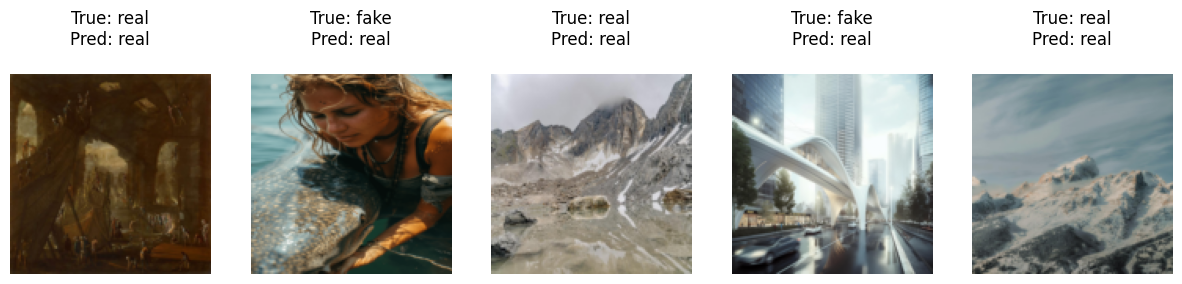

In [ ]:
import random
import matplotlib.pyplot as plt
import torch

# --- Make sure this function is defined first ---
def predict_image(model, image_tensor, device):
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        outputs = model(image_tensor)
        probs = torch.exp(outputs)           # Convert log_softmax to probabilities
        confidence, predicted = torch.max(probs, 1)
    return predicted.item(), confidence.item()

# Create test_dataset variable (this was missing!)
test_dataset = datasets.ImageFolder(root=f"{path}/test", transform=transform)

# --- Number of random images to display ---
num_samples = 5
plt.figure(figsize=(15, 5))

for i in range(num_samples):
    # Pick a random image from the test dataset
    idx = random.randint(0, len(test_dataset) - 1)
    sample_img, label = test_dataset[idx]

    # Prepare tensor for prediction
    img_tensor = sample_img.unsqueeze(0).to(device)
    pred_idx, confidence = predict_image(model, img_tensor, device)

    # Show image with title
    plt.subplot(1, num_samples, i + 1)
    plt.imshow(sample_img.permute(1, 2, 0))  # CHW → HWC
    plt.title(f"True: {test_dataset.classes[label]}\nPred: {test_dataset.classes[pred_idx]}\n")
    plt.axis("off")

plt.show()

Ready to process images. Please upload a file to start.
To stop, click the 'Stop' button in the Google Colab UI.


Saving Starry_Night.jpg to Starry_Night.jpg
User uploaded: Starry_Night.jpg


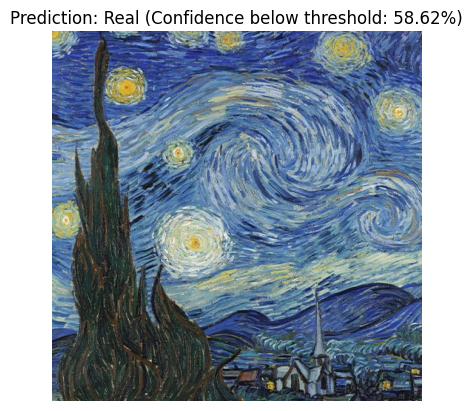

Saving Stable_Art_Sky(Fake).png to Stable_Art_Sky(Fake).png
User uploaded: Stable_Art_Sky(Fake).png


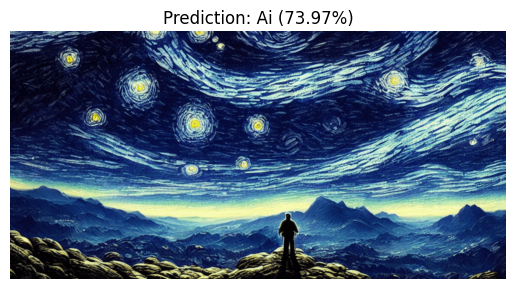

Saving Cat_AI.webp to Cat_AI.webp
User uploaded: Cat_AI.webp


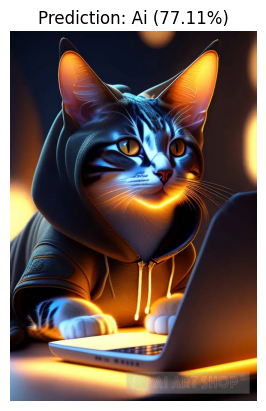

Saving Real_2.jpg to Real_2.jpg
User uploaded: Real_2.jpg


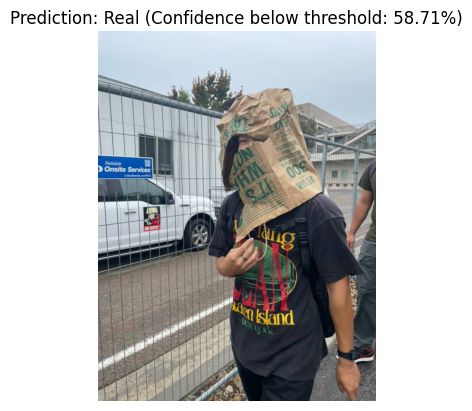

Saving Demonstration1.jpg to Demonstration1.jpg
User uploaded: Demonstration1.jpg


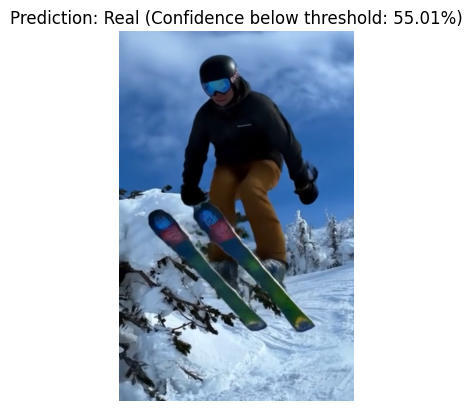

Saving Freaky_Philip__3.jpg to Freaky_Philip__3.jpg
User uploaded: Freaky_Philip__3.jpg


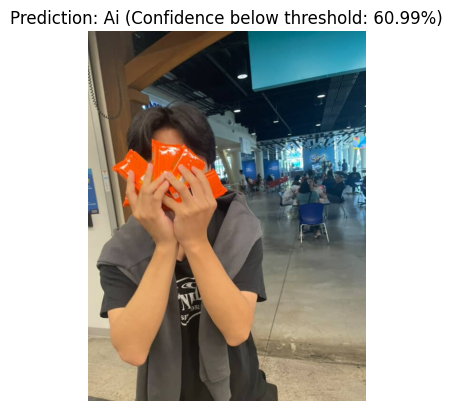

Saving Yellow_Flower(Real).jpg to Yellow_Flower(Real).jpg
User uploaded: Yellow_Flower(Real).jpg


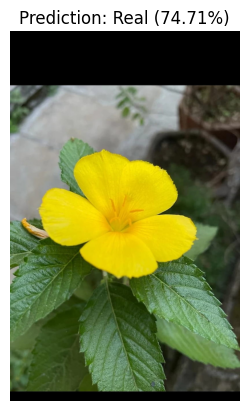

Saving Doggo_toy.webp to Doggo_toy.webp
User uploaded: Doggo_toy.webp


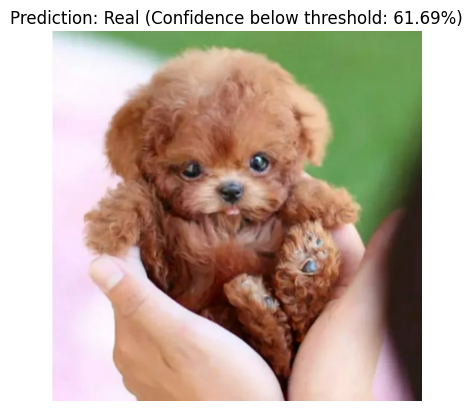

Saving Doog.avif to Doog.avif
User uploaded: Doog.avif


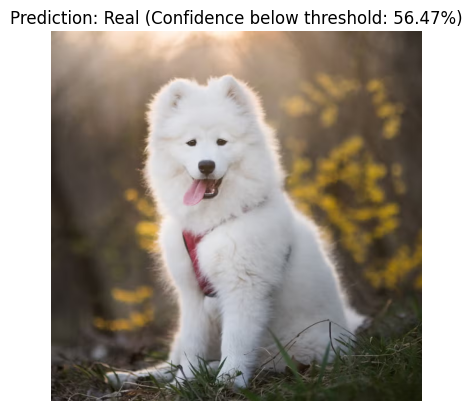

Saving Real_1.jpg to Real_1.jpg
User uploaded: Real_1.jpg


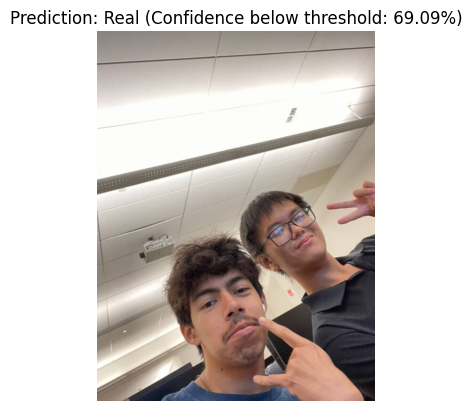

Saving AI_dog.webp to AI_dog.webp
User uploaded: AI_dog.webp


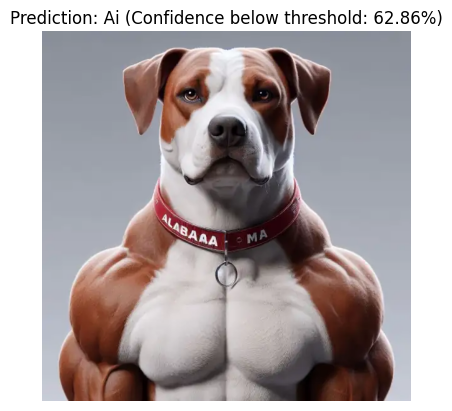

Saving Real_6.jpg to Real_6.jpg
User uploaded: Real_6.jpg


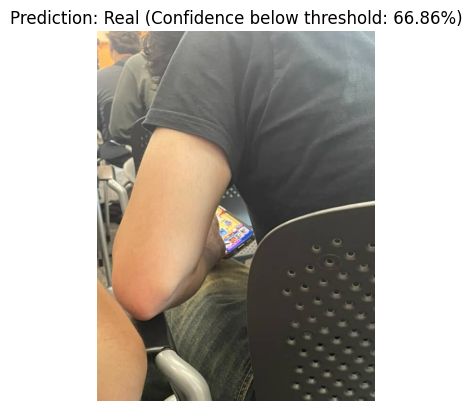

Saving Curt.jpg to Curt (1).jpg
User uploaded: Curt (1).jpg


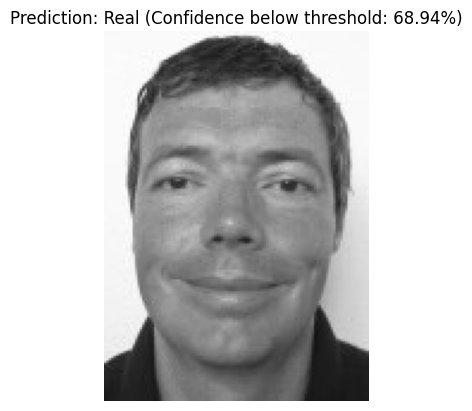

In [ ]:
from PIL import Image
import torchvision.transforms as transforms
import torch
from google.colab import files
import matplotlib.pyplot as plt
import torch.nn.functional as F
import os

# Assuming loaded_model and device are defined elsewhere in your notebook
# loaded_model = ...
# device = torch.device(...)

# --- Inference preprocessing (deterministic) ---
inference_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    return inference_transform(image).unsqueeze(0)

# --- Prediction function ---
def predict_image(model, image_tensor, device):
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        outputs = model(image_tensor)
        probs = F.softmax(outputs, dim=1).squeeze().cpu().tolist()
        predicted_idx = torch.argmax(outputs).item()
    return predicted_idx, probs

# --- Classes and confidence threshold ---
classes = ["Ai", "Real"]
confidence_threshold = 0.7

# --- Continuous loop for image processing ---
print("Ready to process images. Please upload a file to start.")
print("To stop, click the 'Stop' button in the Google Colab UI.")

while True:
    try:
        uploaded = files.upload()

        if not uploaded:
            print("No file uploaded. Waiting for the next upload...")
            continue

        for filename in uploaded.keys():
            print(f"User uploaded: {filename}")
            image_tensor = preprocess_image(filename)
            predicted_idx, probs = predict_image(loaded_model, image_tensor, device)
            predicted_class = classes[predicted_idx]
            max_prob = probs[predicted_idx]

            if max_prob < confidence_threshold:
                prediction_text = f"Prediction: {predicted_class} (Confidence below threshold: {max_prob*100:.2f}%)"
            else:
                prediction_text = f"Prediction: {predicted_class} ({max_prob*100:.2f}%)"

            img = Image.open(filename).convert("RGB")
            plt.imshow(img)
            plt.title(prediction_text)
            plt.axis("off")
            plt.show()

            os.remove(filename)

    except KeyboardInterrupt:
        print("\nProcess interrupted by user. Exiting loop.")
        break
    except Exception as e:
        print(f"An error occurred: {e}. Waiting for the next upload...")
        continue